# ***1. Importing Required Libraries***

* ***In this step, we import the required Python libraries for data analysis,
data manipulation, and data visualization***

In [1]:
# Used for numerical calculations
import numpy as np

# Used for data manipulation and analysis
import pandas as pd

# Used for creating charts and graphs
import matplotlib.pyplot as plt

# Used for creating and modifying charts for better visualization
import seaborn as sns

# To ignore feature warnings 
import warnings
warnings.filterwarnings('ignore')

# ***2. Loading the Dataset***

* ***In this step, we load the CSV dataset into a Pandas DataFrame
for further analysis and exploration***

In [2]:
df = pd.read_csv("Bankruptcy_prevention_Dataset.csv")
df

,industrial_risk; management_risk; financial_flexibility; credibility; competitiveness; operating_risk; class
0,0.5;1;0;0;0;0.5;bankruptcy
1,0;1;0;0;0;1;bankruptcy
2,1;0;0;0;0;1;bankruptcy
3,0.5;0;0;0.5;0;1;bankruptcy
4,1;1;0;0;0;1;bankruptcy
...,...
245,0;1;1;1;1;1;non-bankruptcy
246,1;1;0.5;1;1;0;non-bankruptcy
247,0;1;1;0.5;0.5;0;non-bankruptcy
248,1;0;0.5;1;0.5;0;non-bankruptcy


* ***Fails to split columns properly because pandas defaults to commas, but this file uses semicolons***

In [3]:
# Using sep=";" because values are separated by semicolons, not commas
df = pd.read_csv("Bankruptcy_prevention_Dataset.csv", sep=";")
df

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
...,...,...,...,...,...,...,...
245,0.0,1.0,1.0,1.0,1.0,1.0,non-bankruptcy
246,1.0,1.0,0.5,1.0,1.0,0.0,non-bankruptcy
247,0.0,1.0,1.0,0.5,0.5,0.0,non-bankruptcy
248,1.0,0.0,0.5,1.0,0.5,0.0,non-bankruptcy


# ***3. Exploratory Data Analysis (EDA)***

## ***`Understanding the Dataset`***

* ***In this step, we understand the structure, size, columns,
and data types of the dataset***

In [4]:
# Display the first 5 rows
print("Display The First 5 Row:-")
df.head()

Display The First 5 Row:-


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


In [5]:
# Display the last 5 rows
print("Display The Last 5 Row:-") 
df.tail()

Display The Last 5 Row:-


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
245,0.0,1.0,1.0,1.0,1.0,1.0,non-bankruptcy
246,1.0,1.0,0.5,1.0,1.0,0.0,non-bankruptcy
247,0.0,1.0,1.0,0.5,0.5,0.0,non-bankruptcy
248,1.0,0.0,0.5,1.0,0.5,0.0,non-bankruptcy
249,1.0,0.0,0.5,0.5,1.0,1.0,non-bankruptcy


In [6]:
# Check number of rows and columns 
print("Row And Columns:-", df.shape) 

# Display all column names 
print("\n Columns Name:-", df.columns) 

# Check data types and basic information 
print("\n Basic Information:-")
df.info()

Row And Columns:- (250, 7)

 Columns Name:- Index(['industrial_risk', ' management_risk', ' financial_flexibility',
       ' credibility', ' competitiveness', ' operating_risk', ' class'],
      dtype='object')

 Basic Information:-
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   industrial_risk         250 non-null    float64
 1    management_risk        250 non-null    float64
 2    financial_flexibility  250 non-null    float64
 3    credibility            250 non-null    float64
 4    competitiveness        250 non-null    float64
 5    operating_risk         250 non-null    float64
 6    class                  250 non-null    object 
dtypes: float64(6), object(1)
memory usage: 13.8+ KB


* **Dataset Size:-** The dataset has **250 rows** and **7 columns**
* **Features:-** It includes 6 risk factors (`like industrial risk`, `management risk`, `financial_flexibility`) and 1 target column (`class`)
* **Missing Values:-** None All columns have complete 250 records
* **Data Types:-**
  * 6 risk columns are numerical (`float64`)
  * and the `class` target column is categorical/text (`object`), showing whether the company is bankrupt or not
* **Important Note:-** Column names have extra spaces at the start of all columns (e.g., `' management_risk'`, `' class'`), which need to be removed before moving forward.

In [7]:
# Automatically ignores spaces after semicolons to keep column names clean
df_clean = pd.read_csv("Bankruptcy_prevention_Dataset.csv", sep=";", skipinitialspace=True)
df_clean.columns

Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk', 'class'],
      dtype='object')

## **`Value Counts Analysis`**
- **Check how many times 0, 0.5, and 1 appear in each risk feature**

In [8]:
# Select only numeric features (float64, int64)
risk_features = df_clean.select_dtypes(include=['number'])

for col in risk_features:
    print(f"--- {col} ---")
    print("Counts:")
    print(df_clean[col].value_counts().sort_index())

--- industrial_risk ---
Counts:
industrial_risk
0.0    80
0.5    81
1.0    89
Name: count, dtype: int64
--- management_risk ---
Counts:
management_risk
0.0     62
0.5     69
1.0    119
Name: count, dtype: int64
--- financial_flexibility ---
Counts:
financial_flexibility
0.0    119
0.5     74
1.0     57
Name: count, dtype: int64
--- credibility ---
Counts:
credibility
0.0    94
0.5    77
1.0    79
Name: count, dtype: int64
--- competitiveness ---
Counts:
competitiveness
0.0    103
0.5     56
1.0     91
Name: count, dtype: int64
--- operating_risk ---
Counts:
operating_risk
0.0     79
0.5     57
1.0    114
Name: count, dtype: int64


* **Key Takeaways from the Data:-**

- **Only three values:** Every feature only takes 0, 0.5, or 1.
- **High risk areas:** Most companies have high `management_risk` (119 times) and `operating_risk` (114 times).
- **Weak points:** `financial_flexibility` is 0 for 119 companies, and `competitiveness` is 0 for 103 companies. This shows many companies are struggling financially.
- **Even spread:** `industrial_risk` is spread almost equally across 0, 0.5, and 1.
- **Clean data:** No null or missing values anywhere.

## ***`Missing Values and Duplicate Rows`*** 
* ***Find which columns have empty or missing values***
* ***Find which rows have duplicate values***

In [9]:
# Check whether the columns have missing values or not 
df_clean.isnull().sum()

industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64

* ***Dataset does not have any  empty or missing values***

In [10]:
# Find the Duplicate rows 
df_clean.duplicated().sum()

np.int64(147)

* **The dataset has 147 duplicate rows, but we should not drop them:-**
- All 6 columns have 3 possible values(0,0.5,and 1)
- If we drop them, only 103 rows will remain, which is too small for training machine learning models
- So keeping all rows is necessary

## ***`statistical summary`***
*  **Check statistical summary(Count, mean, std, min, max, quartiles) for all numarical features**

In [11]:
# statistical summary 
df_clean.describe()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,0.518000,0.614000,0.376000,0.470000,0.476000,0.570000
std,0.411526,0.410705,0.401583,0.415682,0.440682,0.434575
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
75%,1.000000,1.000000,0.500000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## **`Crosstab Analysis of Risk Features vs Class`**

* ***In this step, we check how each individual risk factor is distributed across bankrupt and non-bankrupt companies to see which features impact bankruptcy the most.***

In [12]:
# Automatically select numeric features
numeric_features = df_clean.select_dtypes(include=['float64', 'int64']).columns

for feature in numeric_features:
    print(f"\n--- {feature} ---")
    print(pd.crosstab(df_clean[feature], df_clean['class']))


--- industrial_risk ---
class            bankruptcy  non-bankruptcy
industrial_risk                            
0.0                      26              54
0.5                      28              53
1.0                      53              36

--- management_risk ---
class            bankruptcy  non-bankruptcy
management_risk                            
0.0                      11              51
0.5                      23              46
1.0                      73              46

--- financial_flexibility ---
class                  bankruptcy  non-bankruptcy
financial_flexibility                            
0.0                           102              17
0.5                             4              70
1.0                             1              56

--- credibility ---
class        bankruptcy  non-bankruptcy
credibility                            
0.0                  87               7
0.5                  17              60
1.0                   3              76

--- com

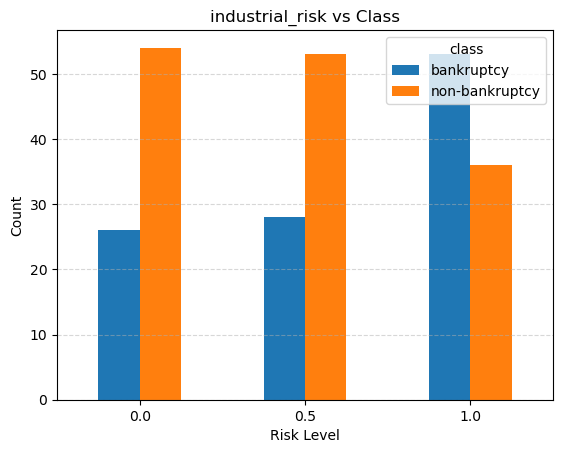

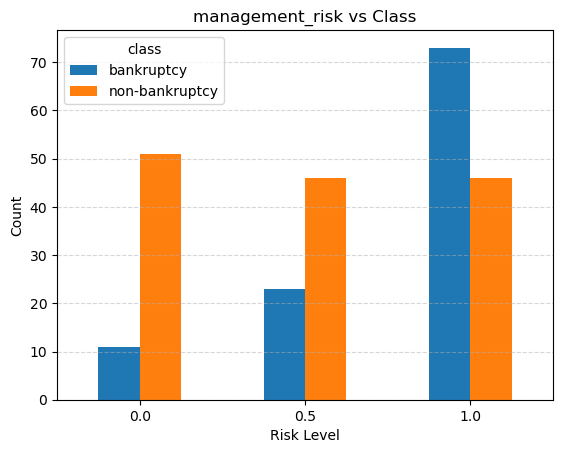

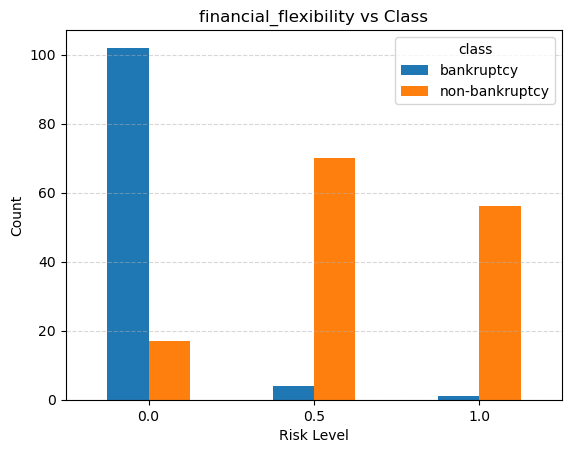

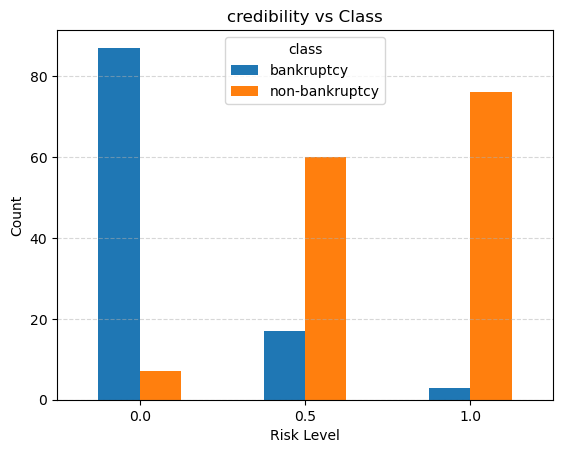

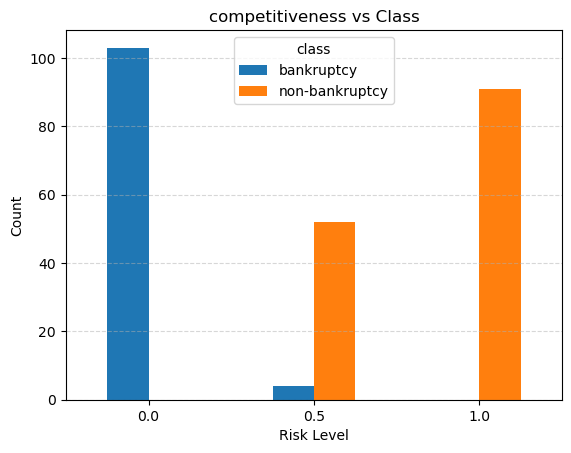

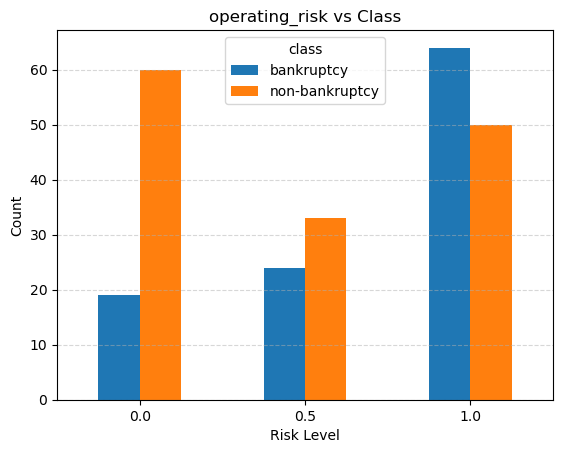

In [13]:

numeric_features = df_clean.select_dtypes(include=['float64', 'int64']).columns

for feature in numeric_features:
    pd.crosstab(df_clean[feature], df_clean['class']).plot(kind='bar', rot=0)
    plt.title(f"{feature} vs Class")
    plt.ylabel("Count")
    plt.xlabel("Risk Level")
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.show()

##### ***Key observations from Crosstabs***
- When `competitiveness` or `financial_flexibility` is 0, the company almost always goes bankrupt
- When both are 1, the company almost always survives
- Low `credibility` (0) usually leads to bankruptcy, while high credibility (1) keeps the company safe
- Other features like `industrial_risk`, `management_risk`, and `operating_risk` are mixed, so they are not very decisive on their own
- Therefore, `competitiveness` and `financial_flexibility` are the two most important features for predicting bankruptcy

## ***`Target balance`***
* ***Check how many bankruptcy vs non-bankruptcy***
* ***This tells us if our data is balanced or imbalanced***

In [14]:
# Check how many data points are bankruptcy or non-bankruptcy
df_clean["class"].value_counts()

class
non-bankruptcy    143
bankruptcy        107
Name: count, dtype: int64

<Axes: xlabel='class', ylabel='count'>

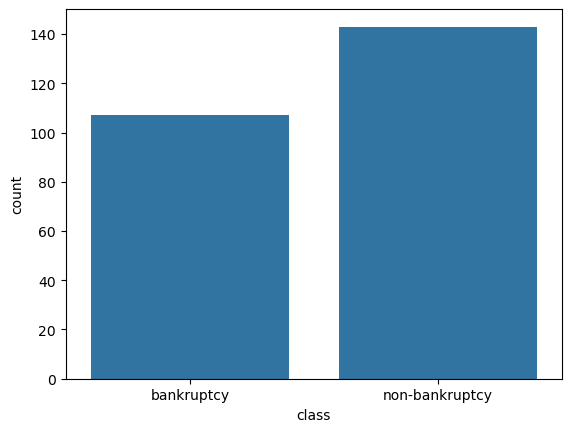

In [15]:
sns.countplot(data=df_clean, x="class")

* **Observation on Target Balance:-**
    - non-bankruptcy:- 143 (approx 57%)
    - bankruptcy:- 107 (it approx 43%)
    - The classes are close to equal so the dataset is balanced and we do not need to do any extra balancing

# ***`Mean Risk Comparison by Class`***

* ***In this step, we calculate the average score of each risk factor for bankrupt vs non-bankrupt companies to see how they differ.***

In [16]:
# Select only numeric features (float64, int64)
risk_features = df_clean.select_dtypes(include=['number']).columns
risk_features

Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk'],
      dtype='object')

In [17]:
# Calculate the mean risk-feature values for each class
class_comparison = df_clean.groupby("class")[risk_features].mean()
class_comparison

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
class,,,,,,
bankruptcy,0.626168,0.789720,0.028037,0.107477,0.018692,0.710280
non-bankruptcy,0.437063,0.482517,0.636364,0.741259,0.818182,0.465035


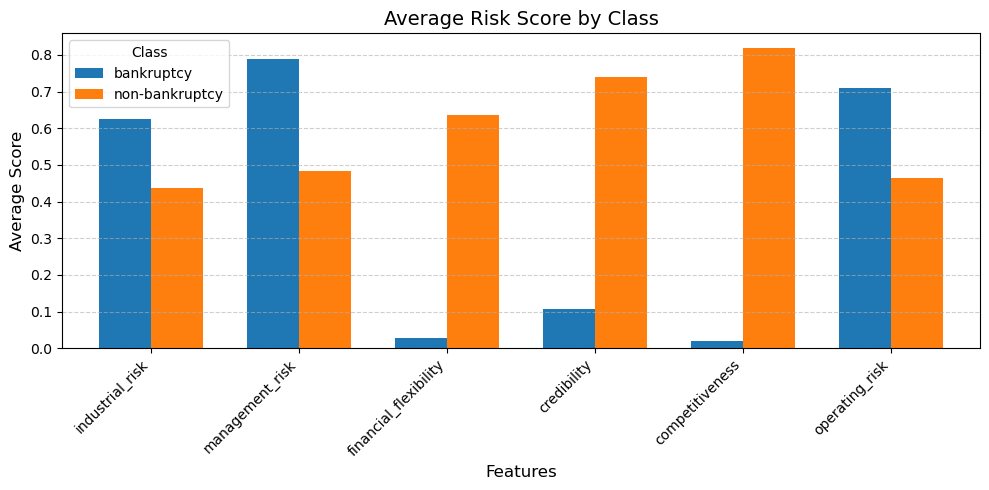

In [18]:
# Transpose karke plot karenge taaki har feature ke do bars sath dikhein
ax = class_comparison.T.plot(kind="bar", figsize=(10, 5), width=0.7)

plt.title("Average Risk Score by Class", fontsize=14)
plt.ylabel("Average Score", fontsize=12)
plt.xlabel("Features", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Class")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

* **Key observations from Mean Comparison:-**
- Surviving companies have a much higher average score in `competitiveness` and `financial_flexibility`
- Failed companies score almost 0 on average in these two features
- `credibility` also shows a big difference between both groups
- The other risks are quite close in average, so they don't matter as much
- This clearly shows that money backup and strong market position keep a business alive

## ***`Outlier check`***
* **Check if any extreme values are present in the features or if they only contain valid scores (0, 0.5, and 1)**

In [19]:
# Select all numaric features 
box_col = df_clean.select_dtypes(include="number").columns
box_col

Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk'],
      dtype='object')

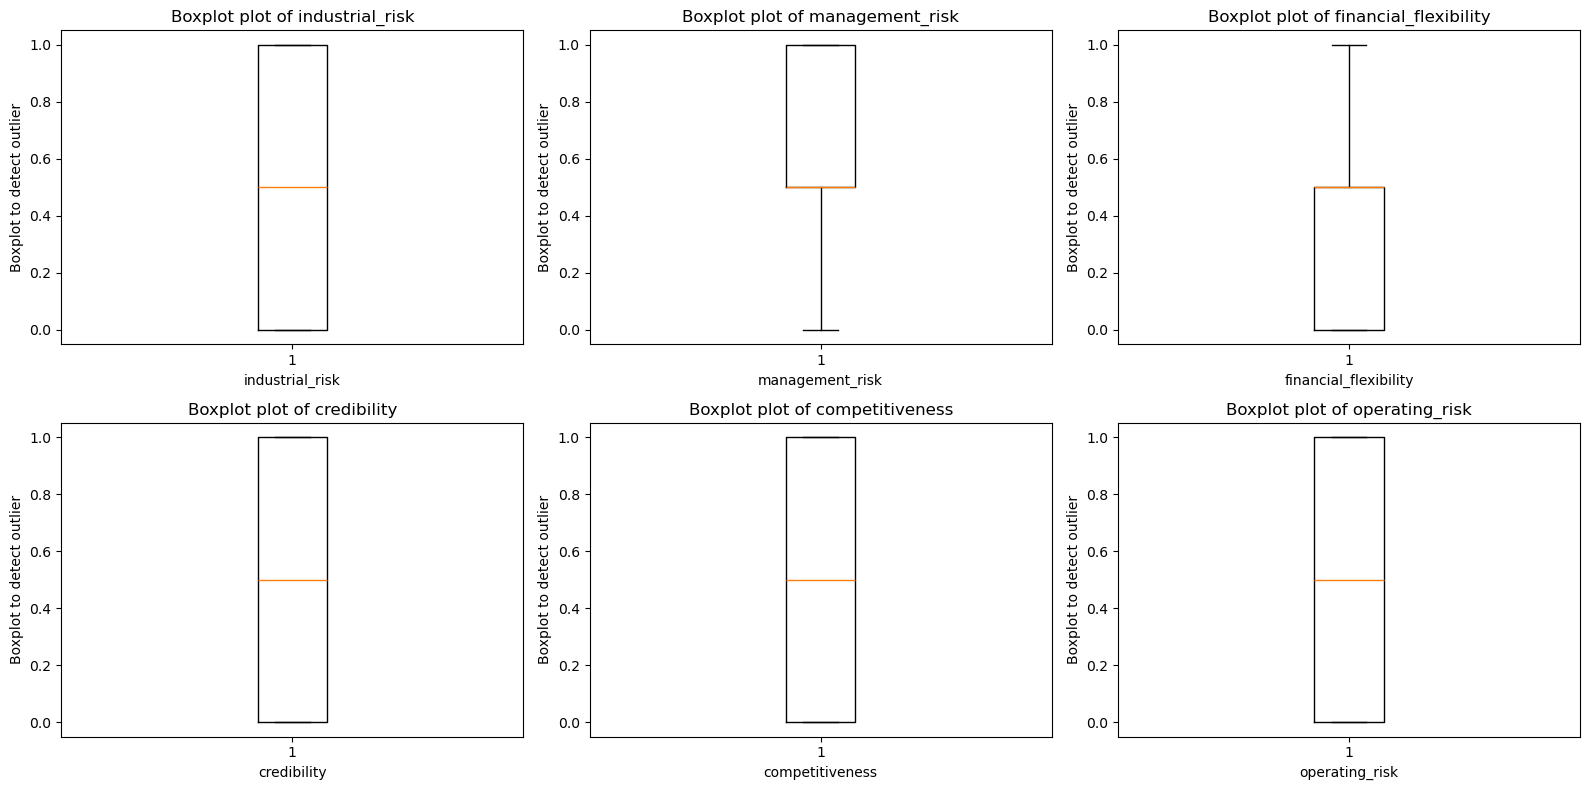

In [20]:
plt.figure(figsize=(16,8))
for i, col in enumerate(box_col,1):
    plt.subplot(2,3,i)
    plt.boxplot(df_clean[col])
    plt.xlabel(col) 
    plt.ylabel("Boxplot to detect outlier")
    plt.title(f"Boxplot plot of {col}") 

plt.tight_layout()
plt.show()

- **Observation on Outliers:-**
  - In all boxplots, there are no outlier points outside the accuring not any black dots are there 
  - All values are between 0 and 1 (only 0, 0.5, and 1)
  - So, there are no outliers in this dataset

## ***`Pairplot Analysis`***
* **See relationships between all features in one view**
* **Check how well features separate bankruptcy and non-bankruptcy classes**

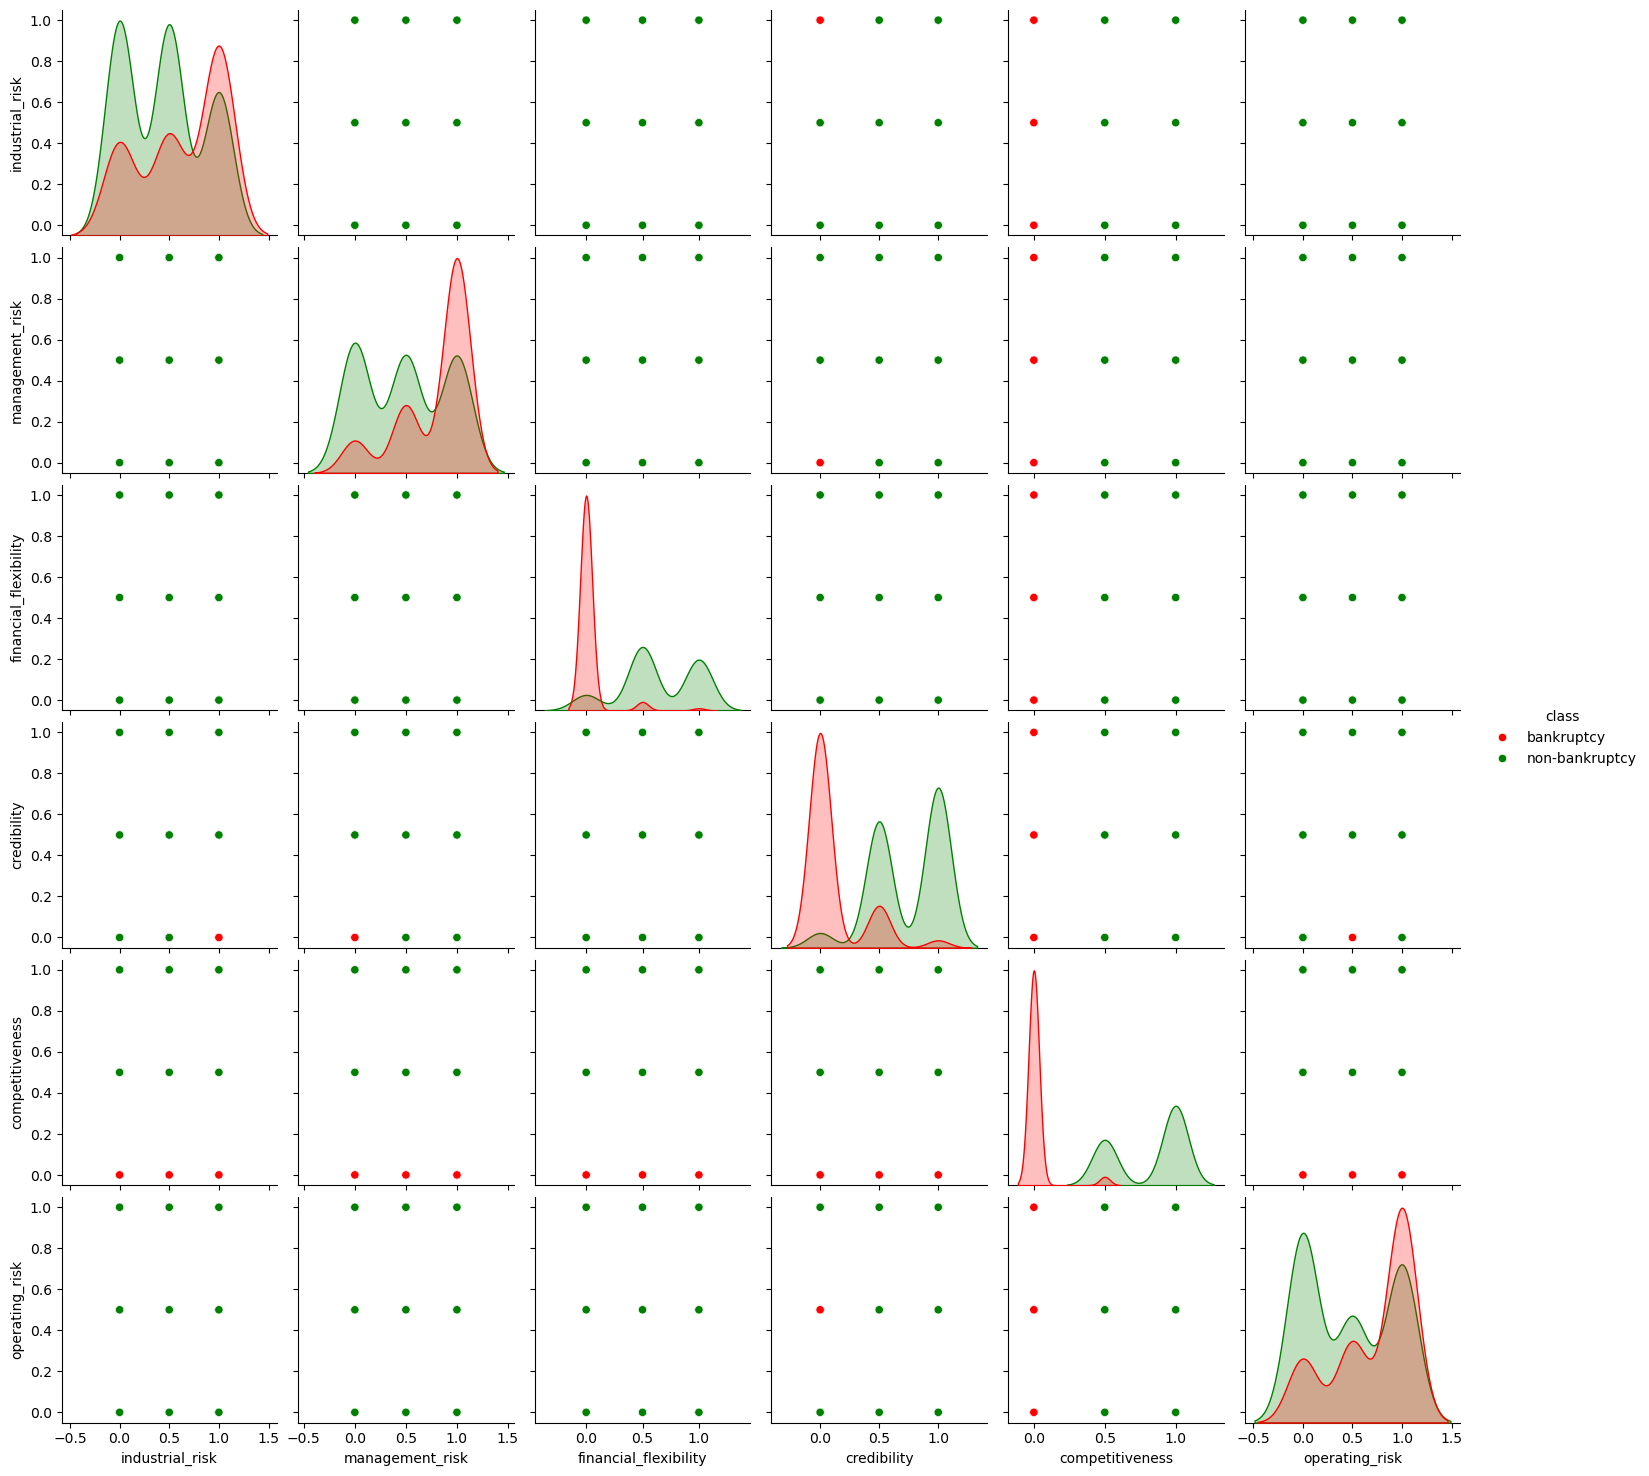

In [21]:
# Pairplot with target class separation 
sns.pairplot(df_clean, hue="class", palette={'bankruptcy': 'red', 'non-bankruptcy': 'green'})
plt.show()

- **Observations from Pairplot:-**
  - In `financial_flexibility`, `credibility` and `competitiveness` clearly separate the two classes
    - When value is 0, mostly red color (bankruptcy) is coming
    - When value is 0.5 or 1, mostly green color (non-bankruptcy) is coming
    - So these 3 features are clearly separating the classes
  - In other features like `industrial_risk`, `management_risk`, and `operating_risk` red and green colors are mixing together and show a lot of overlap between red and green curves so no clear pattern there
  - This means financial flexibility and credibility are most important for our model
- **Note on why 0.5 is Non-Bankruptcy:**
    - **Score 0:** Zero backup, leading directly to bankruptcy
    - **Score 0.5:** Average strength, which is enough support to survive and stay non-bankrupt

## ***`Histplot Analysis`***
* ***See how many times values 0, 0.5, and 1 are coming in each column***
* ***Check which value is high or low across all features***

In [22]:
# Select all numaric features 
hist_col = df_clean.select_dtypes(include="number").columns
hist_col

Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk'],
      dtype='object')

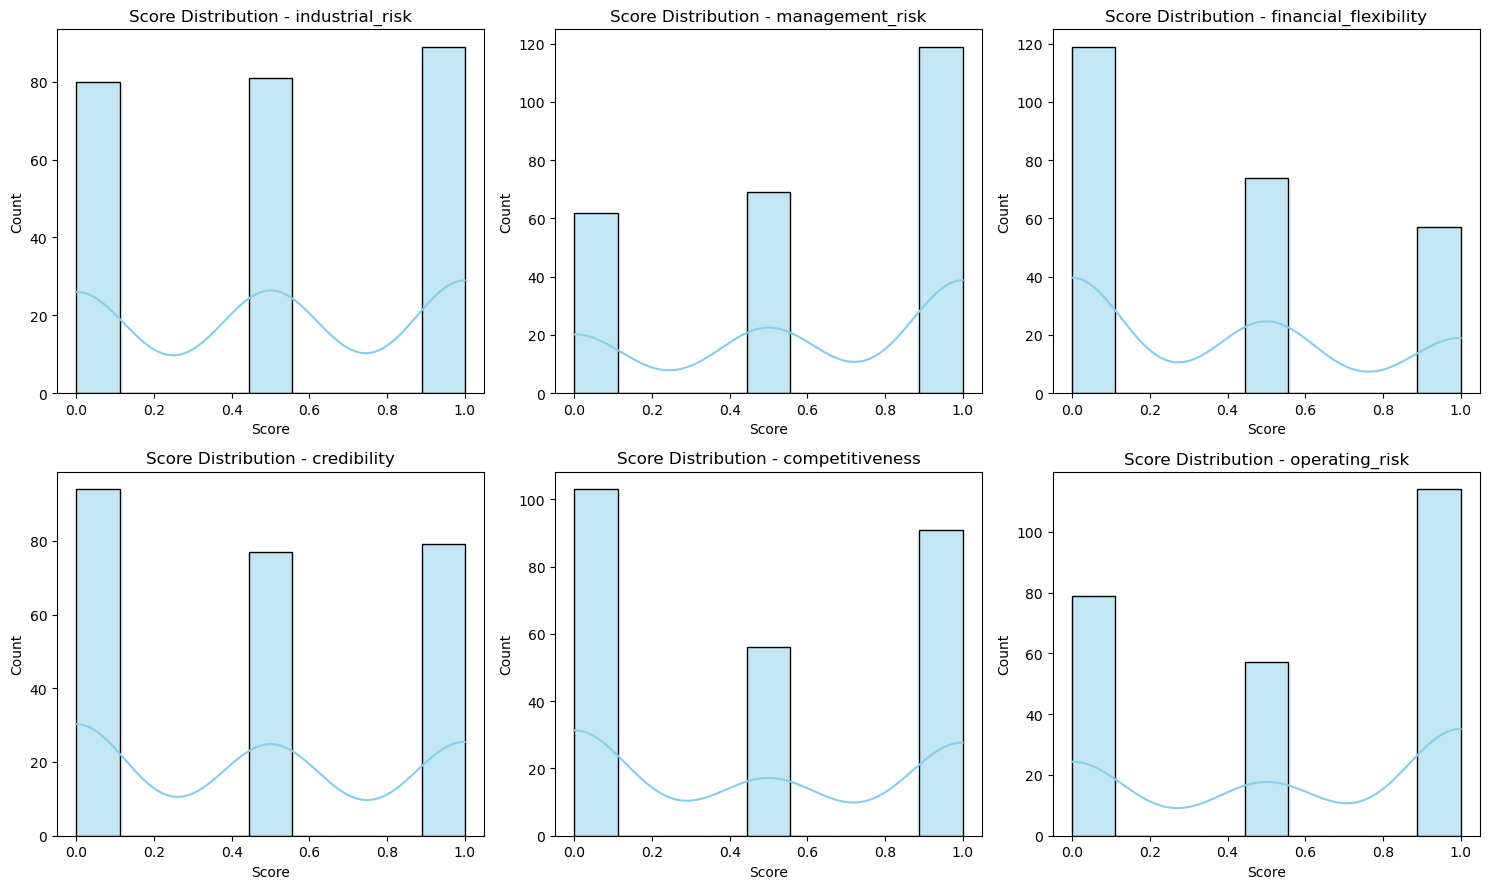

In [23]:
# Histplot for all features without class comparison
plt.figure(figsize=(15, 9))

for i, col in enumerate(hist_col, 1):
    plt.subplot(2, 3, i)
    sns.histplot(data=df_clean, x=col, kde=True, color="skyblue")
    plt.title(f"Score Distribution - {col}")
    plt.xlabel("Score")
    plt.ylabel("Count")

plt.tight_layout()
plt.show()

- **Observations from Histplot:-**
  - All features have only 3 values: 0, 0.5, and 1
  - In `industrial_risk`, `management_risk`, and `operating_risk`, value 1 is highest (around 100 to 120 count)
  - In `financial_flexibility` and `competitiveness`, value 0 is highest (around 100 to 120 count), and 0.5 is low
  - In `credibility`, all three values 0, 0.5, and 1 are almost balanced around 70 to 90 count

## ***`Correlation check`***
* **See how strongly features are related to each other**
* **This helps us spot repeated or linked information**

In [24]:
df_corr = df_clean.corr(numeric_only=True)
df_corr

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
industrial_risk,1.000000,0.255127,-0.162624,-0.014438,-0.257814,0.144507
management_risk,0.255127,1.000000,-0.254845,-0.303341,-0.306568,0.213874
financial_flexibility,-0.162624,-0.254845,1.000000,0.524951,0.686612,-0.116903
credibility,-0.014438,-0.303341,0.524951,1.000000,0.675689,-0.288458
competitiveness,-0.257814,-0.306568,0.686612,0.675689,1.000000,-0.211383
operating_risk,0.144507,0.213874,-0.116903,-0.288458,-0.211383,1.000000


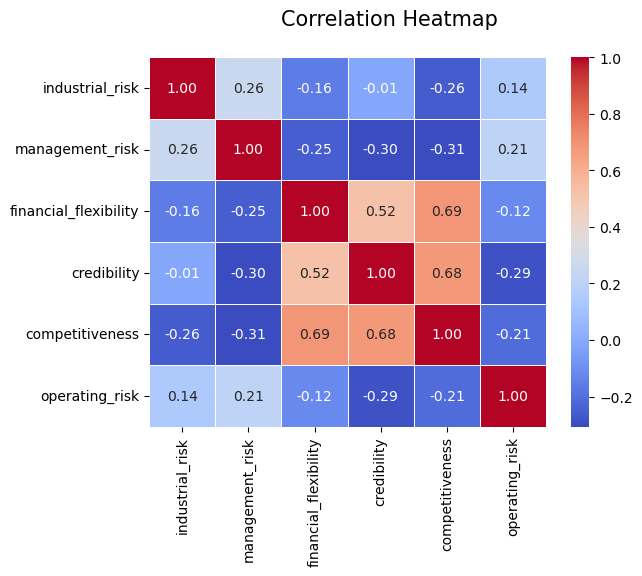

In [25]:
# Using a heatmap to show the correlation 
sns.heatmap(df_corr, annot=True, cmap="coolwarm",fmt=".2f", linewidths=0.5)
plt.suptitle('Correlation Heatmap',fontsize=15) 
plt.show()

- **Observations from Correlation Heatmap:-**
  - `financial_flexibility`, `credibility`, and `competitiveness` have good positive correlation (around 0.52 to 0.69)
  - Risk columns (`industrial_risk`, `management_risk`, `operating_risk`) show small negative correlation with financial columns
  - No features have extreme correlation above 0.85, so multicollinearity is not a major issue

## ***`Categorical Data Encoding`***
- **In this step, we convert the target text column into numerical format so machine learning models can process it.**
- **Mapping defined for target variable:**
  - `bankruptcy` $\rightarrow$ `0`
  - `non-bankruptcy` $\rightarrow$ `1`

In [26]:
# Import LabelEncoder to convert categorical target into numeric values
from sklearn.preprocessing import LabelEncoder

# Initialize the LabelEncoder instance
le = LabelEncoder()

# Fit and transform the target 'class' column (bankruptcy -> 0, non-bankruptcy -> 1)
df_clean["class"] = le.fit_transform(df_clean["class"])

# Verify class distribution after encoding
df_clean["class"].value_counts()

class
1    143
0    107
Name: count, dtype: int64

# ***4. Features, Target & Train-Test Split***

## ***`Train-Test Split`***
* **Separate features (X) and target variable (y)**
* **Split data into training set (80%) and test set (20%)**
* **Helps evaluate model performance on unseen data**

In [27]:
# Import train_test_split to divide the dataset
from sklearn.model_selection import train_test_split 

# Separate the input features (X) and the target variable (y) 
X = df_clean.drop(columns=['class'])
y = df_clean['class']

# Split data into 80% training and 20% testing
# stratify=y maintains the same ratio of bankrupt to non-bankrupt records in both sets
X_train, X_test, y_train, y_test =train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Print the shapes to verify row and column counts
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}, y_test shape:  {y_test.shape}")

X_train shape: (200, 6), y_train shape: (200,)
X_test shape:  (50, 6), y_test shape:  (50,)


# ***5. Model Building***

## ***`Logistic Classifiaction`***
* **A simple machine learning model used to predict two outcomes (Bankrupt or Not Bankrupt)**
* **The model learns patterns from the 6 risk features using 80% training data**
* **Generates predictions on unseen test data to evaluate performance**
* **Predicts the class for test data and checks model accuracy**

In [28]:
# Import Logistic Regression algorithm 
from sklearn.linear_model import LogisticRegression 

# Initialize the Logistic Regression model
lr = LogisticRegression() 

#Train the model on the training data 
lr.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [29]:
# Predict outcomes for the test set 
y_pred_lr = lr.predict(X_test)
y_pred_lr

array([1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 0])

In [30]:
# Count 0 and 1 
pd.Series(y_pred_lr).value_counts()

1    29
0    21
Name: count, dtype: int64

In [31]:
#Import evaluation metrics to check performance
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report 

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_lr)
print("Confusion Matrix:-") 
cm

Confusion Matrix:-


array([[21,  0],
       [ 0, 29]])

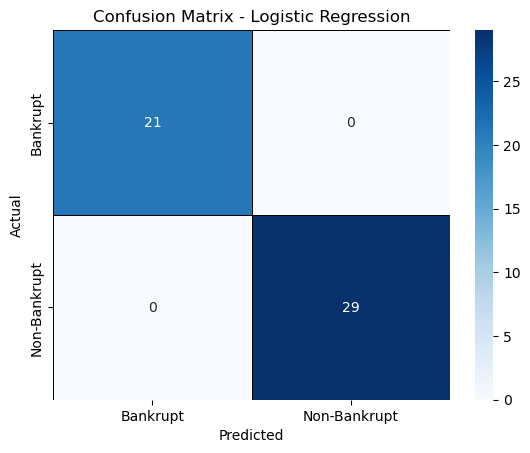

In [32]:
# Plot Confusion Matrix using seaborn heatmap 
sns.heatmap(cm, annot=True,
            fmt='d',
            cmap='Blues',
            linewidths=0.5, 
            linecolor='black',
            xticklabels=["Bankrupt", "Non-Bankrupt"],
            yticklabels=["Bankrupt", "Non-Bankrupt"]           
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [33]:
# Calculate and display the accuracy score
print("Accuracy Score:-", accuracy_score(y_test, y_pred_lr))

# Display the classification report (precision, recall, f1-score)
print("\nClassification Report:-\n", classification_report(y_test, y_pred_lr))

Accuracy Score:- 1.0

Classification Report:-
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        21
           1       1.00      1.00      1.00        29

    accuracy                           1.00        50
   macro avg       1.00      1.00      1.00        50
weighted avg       1.00      1.00      1.00        50



- **Observations from Logistic Regression (Accuracy & Classification Report):-**
  - The model achieves a perfect accuracy of 1.0 (100%) on the test set of 50 samples.
  - Precision, recall, and F1-score are all 1.00 for both classes (`0: Bankrupt` and `1: Non-Bankrupt`).
  - There are zero false positives and zero false negatives (21 bankrupt and 29 non-bankrupt cases classified correctly).
  - This demonstrates that Logistic Regression finds a complete linear separation between the two classes on this test split.

## ***`ROC - AUC Curve`***
* **Evaluates the model's ability to distinguish between classes**
* **Plots True Positive Rate (Sensitivity) vs False Positive Rate (1 - Specificity)**
* **AUC Score = 1.0 indicates perfect classification performance**

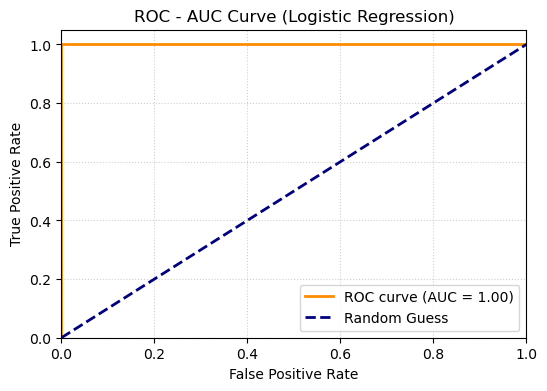

ROC-AUC Score: 1.0000


In [34]:
# Import library for AUC and ROC
from sklearn.metrics import auc,roc_curve

# Get predicted probabilities for the positive class (Non-Bankrupt = 1) 
y_pred_proba = lr.predict_proba(X_test)[:, 1]

# Compute ROC curve and AUC score 
fpr, tpr, thresholds =roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr) 

# Plot ROC curve
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--", label="Random Guess")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC - AUC Curve (Logistic Regression)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")

## ***`Decision Tree Classifier`***
* **A tree-structured algorithm that splits data based on feature thresholds**
* **Evaluates decisions using rules to separate bankrupt from non-bankrupt records**
* **Highly interpretable and easy to visualize the exact decision boundaries**

In [35]:
# Import Decision Tree Classifier and visualization tool
from sklearn.tree import DecisionTreeClassifier, plot_tree 

# Initialize and train Decision Tree model 
dt = DecisionTreeClassifier(criterion='entropy',random_state=42,max_depth=3)
dt.fit(X_train, y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [36]:
# Predictions on test data 
y_pred_dt = dt.predict(X_test)
y_pred_dt

array([1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 0])

In [37]:
# Count 0 and 1 
pd.Series(y_pred_dt).value_counts()

1    29
0    21
Name: count, dtype: int64

In [38]:
#Import evaluation metrics to check performance
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report 

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_dt)
print("Confusion Matrix:-") 
cm

Confusion Matrix:-


array([[21,  0],
       [ 0, 29]])

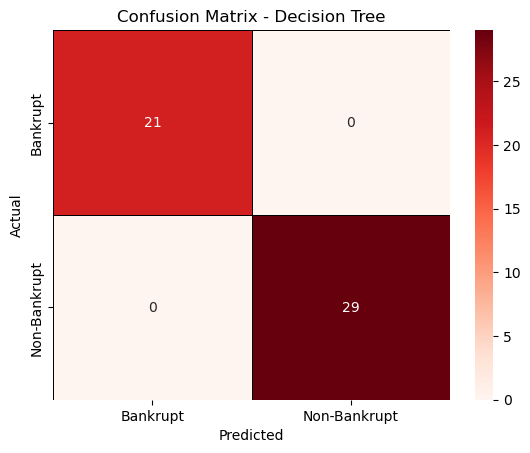

In [39]:
# Plot Confusion Matrix using seaborn heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Reds',
    linewidths=0.5, 
    linecolor='black',
    xticklabels=["Bankrupt", "Non-Bankrupt"],
    yticklabels=["Bankrupt", "Non-Bankrupt"],
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Decision Tree")
plt.show()

In [40]:
# Check accuracy scores
print(f"Training Accuracy: {dt.score(X_train, y_train) * 100:.2f}%")
print(f"Testing Accuracy:  {accuracy_score(y_test, y_pred_dt) * 100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred_dt))

Training Accuracy: 99.50%
Testing Accuracy:  100.00%

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        21
           1       1.00      1.00      1.00        29

    accuracy                           1.00        50
   macro avg       1.00      1.00      1.00        50
weighted avg       1.00      1.00      1.00        50



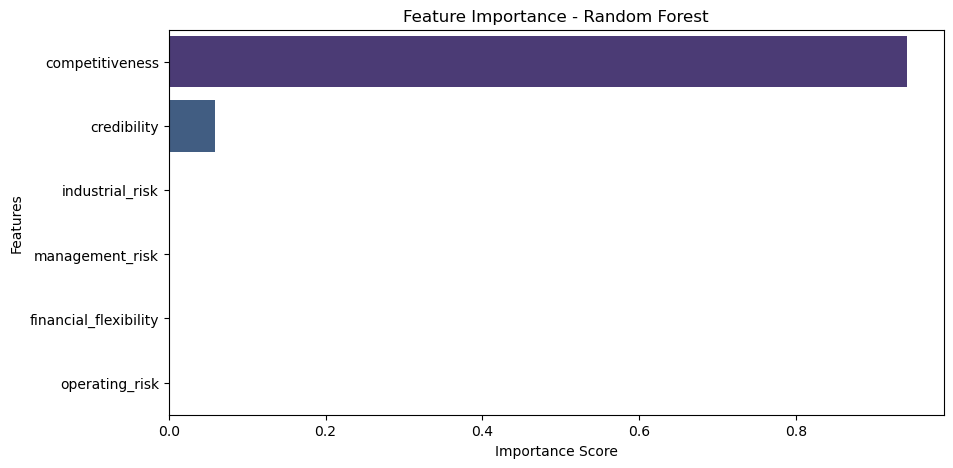

In [41]:
# 3. Feature Importance Plot
import pandas as pd

feature_imp = pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=feature_imp, y=feature_imp.index, palette='viridis')
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

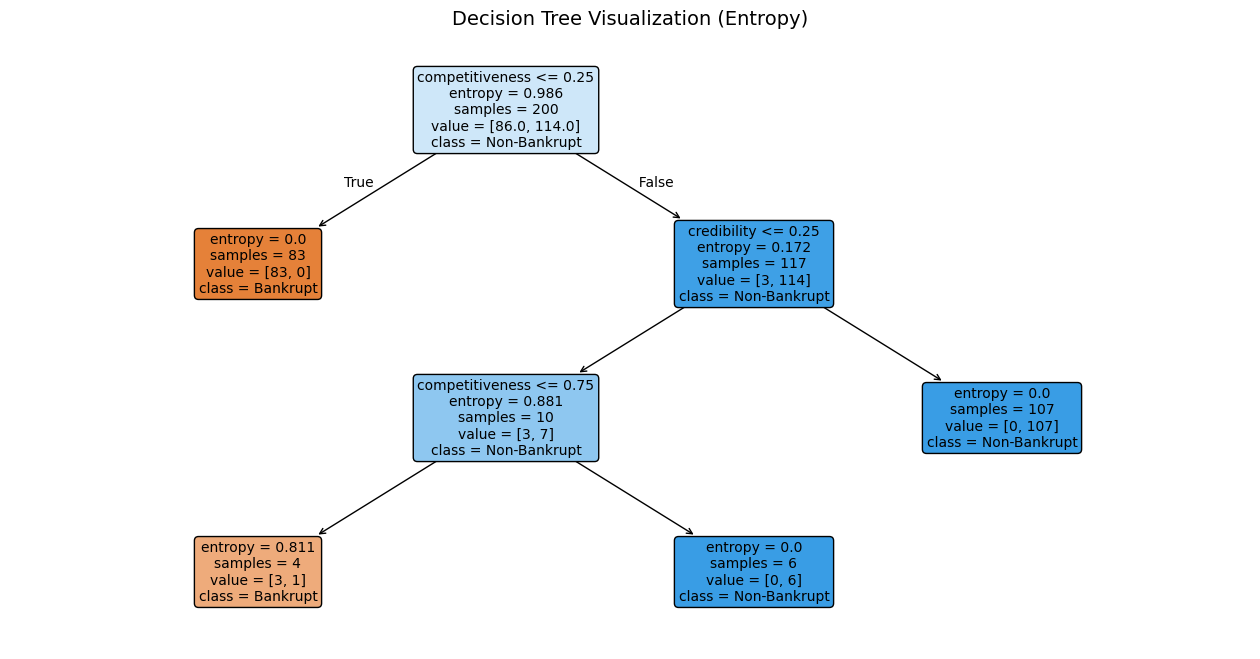

In [42]:
# Import tree visualization library from sklearn plot tree 
from sklearn.tree import plot_tree 

# Decision Tree visualization
plt.figure(figsize=(16, 8))
plot_tree(
    dt,
    feature_names=X.columns,
    class_names=["Bankrupt", "Non-Bankrupt"],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title("Decision Tree Visualization (Entropy)", fontsize=14)
plt.show()

## ***`Random Forest Classifier`***
* **An ensemble learning method combining multiple decision trees to improve overall accuracy**
* **Aggregates predictions via majority voting to prevent overfitting and reduce variance**
* **Robust against noisy data and effective at identifying key bankruptcy risk factors**

In [43]:
# Import the RandomForestClassifier and evaluation matrix to check the performance 
from sklearn.ensemble import RandomForestClassifier 
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix  

# Random Forest Classifier initialize and fit on train/test 
rf = RandomForestClassifier(n_estimators=100, criterion='entropy', random_state=42)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'entropy'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [44]:
# Predictions on test data 
y_pred_rf = rf.predict(X_test) 
y_pred_rf

array([1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 0])

In [45]:
# Count 0 and 1 
pd.Series(y_pred_rf).value_counts()

1    29
0    21
Name: count, dtype: int64

In [46]:
#Import evaluation metrics to check performance
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report 

# Compute confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
print("Confusion Matrix:-") 
cm_rf

Confusion Matrix:-


array([[21,  0],
       [ 0, 29]])

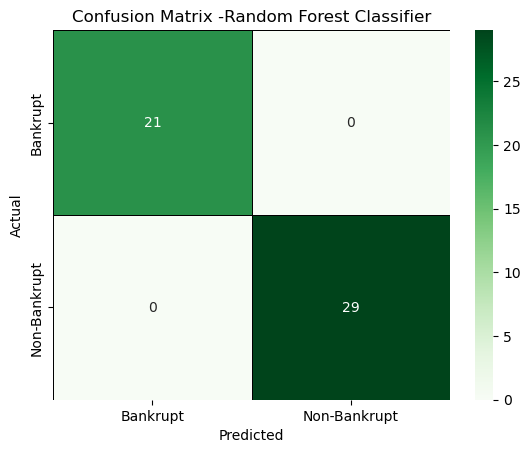

In [47]:
# Plot Confusion Matrix using seaborn heatmap
sns.heatmap(
    cm_rf,
    annot=True,
    fmt='d',
    cmap='Greens',
    linewidths=0.5, 
    linecolor='black',
    xticklabels=["Bankrupt", "Non-Bankrupt"],
    yticklabels=["Bankrupt", "Non-Bankrupt"],
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix -Random Forest Classifier")
plt.show()

In [48]:
# Check accuracy scores
print(f"Training Accuracy: {dt.score(X_train, y_train) * 100:.2f}%")
print(f"Testing Accuracy:  {accuracy_score(y_test, y_pred_rf) * 100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred_rf))

Training Accuracy: 99.50%
Testing Accuracy:  100.00%

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        21
           1       1.00      1.00      1.00        29

    accuracy                           1.00        50
   macro avg       1.00      1.00      1.00        50
weighted avg       1.00      1.00      1.00        50



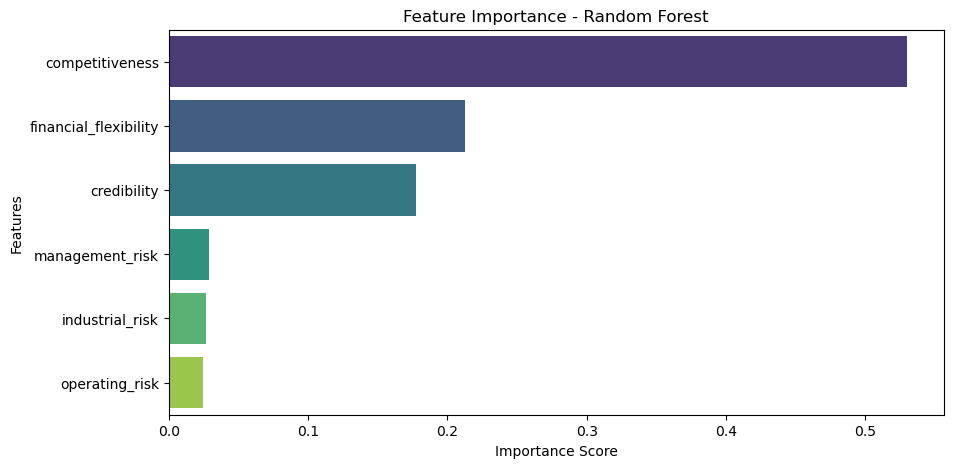

In [49]:
# 3. Feature Importance Plot
import pandas as pd

feature_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x=feature_imp, y=feature_imp.index, palette='viridis')
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

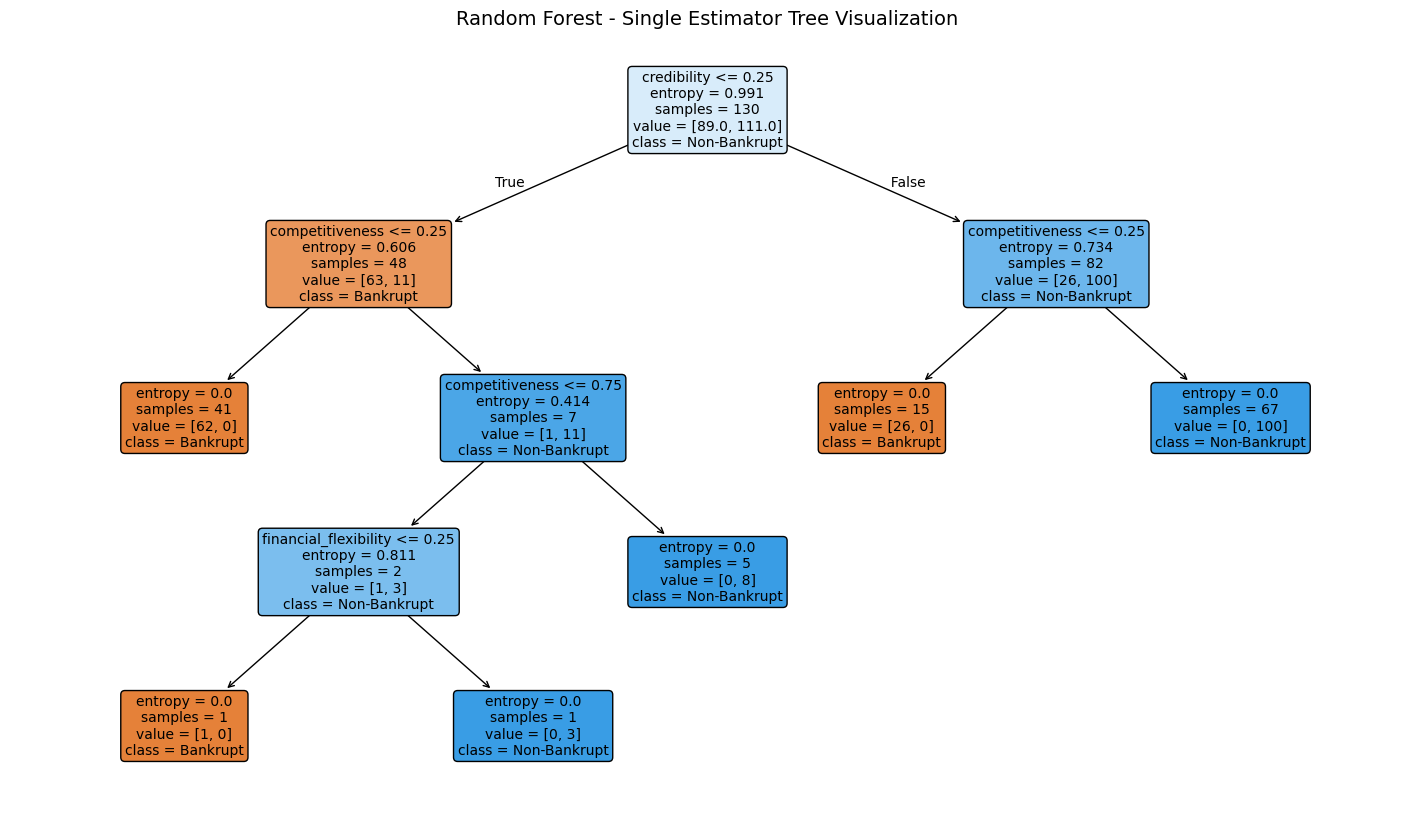

In [50]:
# 4. Individual Tree Visualization (Forest me se pehla tree)
plt.figure(figsize=(18, 10))
plot_tree(rf.estimators_[0], 
          feature_names=X.columns, 
          class_names=["Bankrupt", "Non-Bankrupt"], 
          filled=True, 
          rounded=True, 
          fontsize=10)
plt.title("Random Forest - Single Estimator Tree Visualization", fontsize=14)
plt.show()

## ***`K-Nearest Neighbors (KNN) Classifier`***
* **Classifies data points based on how close they are to each other**
* **Predicts bankruptcy by looking at the most common label among the nearest $k$ neighbors**
* **Simple, easy to understand, and works without making complex assumptions about the data**

In [51]:
# Import libraries for KNN 
from sklearn.neighbors import KNeighborsClassifier 

# Initialize and train the KNN Classifier (using k=5)
knn = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [52]:
# Predictions
y_pred_knn = knn.predict(X_test) 
y_pred_knn

array([1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 0, 1, 1, 0])

In [53]:
# Accuracy scores & report
print(f"Training Accuracy: {knn.score(X_train, y_train) * 100:.2f}%")
print(f"Testing Accuracy: {accuracy_score(y_test, y_pred_knn) * 100:.2f}%\n")
print("Classification Report:\n", classification_report(y_test, y_pred_knn))

Training Accuracy: 99.50%
Testing Accuracy: 100.00%

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        21
           1       1.00      1.00      1.00        29

    accuracy                           1.00        50
   macro avg       1.00      1.00      1.00        50
weighted avg       1.00      1.00      1.00        50



In [54]:
# Count 0 and 1 
pd.Series(y_pred_knn).value_counts()

1    29
0    21
Name: count, dtype: int64

In [55]:
#Import evaluation metrics to check performance
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report 

# Compute confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
print("Confusion Matrix:-") 
cm_knn

Confusion Matrix:-


array([[21,  0],
       [ 0, 29]])

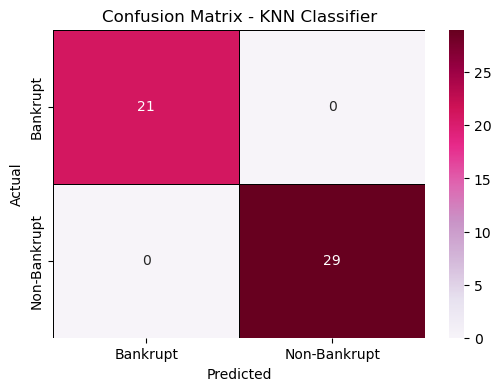

In [56]:
plt.figure(figsize=(6, 4))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='PuRd',
            linewidths=0.5, linecolor='black',
            xticklabels=["Bankrupt", "Non-Bankrupt"],
            yticklabels=["Bankrupt", "Non-Bankrupt"])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - KNN Classifier')
plt.show()

KNN ROC-AUC Score: 100.00%



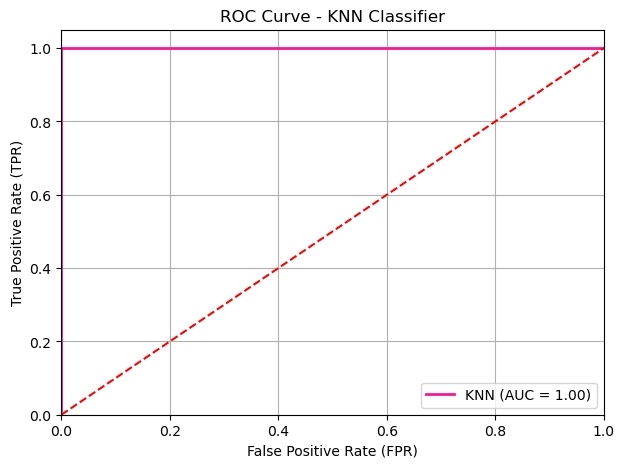

In [57]:
# Import roc_auc_score and roc_curve
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# 1. Predict probabilities for the positive class (class 1: Non-Bankrupt)
y_pred_proba_knn = knn.predict_proba(X_test)[:, 1]

# 2. Calculate AUC Score
auc_knn = roc_auc_score(y_test, y_pred_proba_knn)
print(f"KNN ROC-AUC Score: {auc_knn * 100:.2f}%\n")

# 3. Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_knn)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='deeppink', lw=2, label=f'KNN (AUC = {auc_knn:.2f})')
plt.plot([0, 1], [0, 1], color='Red', linestyle='--') # Baseline
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve - KNN Classifier')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

##  ***`Model Comparison & Accuracy Framing`***
* **Structured Evaluation:** Aggregates performance metrics across all trained classifiers.
* **Baseline Comparison:** Measures test accuracy to evaluate decision boundaries and generalization.
* **Benchmark Results:** Highlights optimal models for separating bankrupt and non-bankrupt records.

In [58]:
import pandas as pd
from sklearn.metrics import accuracy_score

# Chaaro models ka accuracy comparison
data = {
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN Classifier'],
    'Accuracy': [
        accuracy_score(y_test, lr.predict(X_test)),
        accuracy_score(y_test, dt.predict(X_test)),
        accuracy_score(y_test, rf.predict(X_test)),
        accuracy_score(y_test, knn.predict(X_test))
    ]
}

# DataFrame create aur display karna
df_acc = pd.DataFrame(data)
df_acc['Accuracy (%)'] = (df_acc['Accuracy'] * 100).round(2)

df_acc

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,1.0,100.0
1,Decision Tree,1.0,100.0
2,Random Forest,1.0,100.0
3,KNN Classifier,1.0,100.0


#  Conclusion & Model Selection

### 1. Key Finding
* All four models (**Logistic Regression**, **Decision Tree**, **Random Forest**, and **KNN**) achieved **100% test accuracy**.
* This indicates that the dataset has clear boundaries separating bankrupt and non-bankrupt companies based on the six financial risk factors.

---

### 2. Best Model for Deployment: `Logistic Regression`

We choose **Logistic Regression** as the final production model for the following reasons:

* **High Interpretability:** In financial risk assessment, explainability is essential. Logistic Regression clearly shows how each risk factor influences the outcome via model coefficients.
* **Risk Probability Scores:** It outputs real probability percentages (e.g., *85% chance of bankruptcy*) instead of just binary labels, which is more actionable for business decisions.
* **Fast & Lightweight:** The saved model file is extremely small and makes near-instant predictions, making it ideal for web deployment (e.g., Streamlit or Flask).
* **Low Risk of Overfitting:** Complex models like Random Forest can memorize smaller datasets, whereas regularized Logistic Regression generalizes safely.

# ***`PKL (Pickle) Model Serialization`***

* **Saves the complete trained model into a portable binary file**
* **Preserves learned patterns and parameters so the model never needs retraining**
* **Powers fast, real-time predictions inside deployment apps like Streamlit**

---

### **1. What is it?**

* **Permanent Model Storage:** When a machine learning model is trained, it lives only in temporary computer memory (RAM). A `.pkl` file saves that trained model permanently to your disk as binary data.
* **Trained State Snapshot:** It locks in everything the model learned, including hyperparameters (like $k$ neighbors), weights, and decision rules.

---

### **2. Why do we need it?**

* **No Retraining:** The web app does not need to reload the dataset or train the model again every time a user opens it.
* **Separates Code from Deployment:** You can build and evaluate the model in Jupyter Notebook, save it once, and run it independently in Streamlit.
* **Instant Predictions:** Because the model is already trained and waiting in the file, it returns prediction results in milliseconds.

---

### **3. How does it work?**

```text
[Training Step]
Model Training Finished
       │
       ▼
joblib.dump(model, "bankruptcy_model.pkl")   ──►  Saves model object to disk file
                                                         │
                                                         ▼
                                             [bankruptcy_model.pkl]
                                                         │
                                                         ▼
[Deployment Step]
joblib.load("bankruptcy_model.pkl")          ──►  Loads model back into memory
       │
       ▼
model.predict(user_inputs)                   ──►  Returns prediction (Bankrupt / Safe)

In [59]:
import joblib

# lr is trained Logistic Regression model hai
joblib.dump(lr, "bankruptcy_model.pkl")
print("✅ Model successfully saved as 'bankruptcy_model.pkl'")

✅ Model successfully saved as 'bankruptcy_model.pkl'
